# Trabajo Práctico - Parte 1: Algoritmos Genéticos

**Cátedra:** Inteligencia Artificial - Lic. en Sistemas de Información (FCyT - UADER, Oro Verde)
**Integrantes:** Facundo Tomas Hernandez y Facundo Thomas Ramirez
**Año:** 2026

Este notebook resuelve las tres actividades del TP usando **Algoritmos Genéticos (AG)** programados desde cero en Python (NumPy), con el código separado por etapa según el **PROCESO USUAL AG** visto en teoría:

1. Población: conjunto inicial de individuos (soluciones candidatas).
2. Función de aptitud (fitness): puntaje que mide qué tan buena es cada solución.
3. Selección: elegir a los más aptos para que pasen sus genes.
4. Cruzamiento: combinar pares de padres en un punto de cruce.
5. Mutación: alterar al azar algunos genes de los hijos.

Además, se usan distintos métodos de selección de los que menciona la bibliografía de la cátedra (torneo, ruleta y rango).

| Actividad | Problema | Codificación | Selección |
|---|---|---|---|
| 1 | Búsqueda de una cadena de texto | Entera (índice de carácter) | Torneo + elitismo |
| 2.a | Minimizar $f(x,y)=(x-1)^2+(x-y)^4$ | Binaria (como en la diapositiva "Rueda") | Rueda de ruleta |
| 2.b | Maximizar $f(x,y)=2+\sqrt{9-x^2-y^2}$ | Real | Rango lineal + penalización |
| 2.c | Maximizar $f(x,y,z)=z-x^2-15y^2$, $-2<x,y,z<11$ | Real | Torneo + elitismo |
| 3 | Selección de variables en el dataset *Wine* | Binaria (máscara de features) | Torneo (como en el artículo de Warnes) |

## 0. Librerías y configuración general

In [1]:
import time
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla global para que los resultados sean reproducibles.
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.precision", 4)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.2.6 | pandas 2.3.3


---
# ACTIVIDAD 1 - Búsqueda de la cadena de texto

**Objetivo:** encontrar con un AG la cadena
`TARGET = "Los algoritmos genéticos sirven para optimizar"`
y determinar, de forma automática, cuál de los tamaños de población de la lista
`PS = [100, 1000, 50, 200, 300, 50, 500]` se ajusta mejor al problema.

### Modelado del problema
* Individuo (cromosoma): una cadena de la misma longitud que el TARGET (46 caracteres). Cada **gen** es un carácter, representado internamente como un entero = índice dentro de un alfabeto. Así toda la población es una matriz NumPy de enteros de forma `(PS, 46)` y las operaciones se vectorizan.
* Función de aptitud: cantidad de posiciones en las que el individuo coincide con el TARGET (0 a 46). **Se maximiza**; la solución es un individuo con aptitud 46.
* Selección: torneo de tamaño 3 (se toman 3 individuos al azar y gana el de mayor aptitud). Elegimos torneo porque no depende de la escala del fitness y es robusto cuando muchos individuos tienen aptitud parecida.
* Cruzamiento: de un punto (se elige al azar un punto de corte y se intercambian las colas), con probabilidad `PC`.
* Mutación: cada gen del hijo se reemplaza por un carácter aleatorio con probabilidad `PM = 1/L`.
* Elitismo: el mejor individuo de la generación anterior sobrevive siempre (para no perder la mejor solución por azar).

In [2]:
# ============================================================
# ACTIVIDAD 1 - Definición del problema
# ============================================================
TARGET = "Los algoritmos genéticos sirven para optimizar"

# Alfabeto: letras, dígitos, espacio, vocales acentuadas, ñ y algunos signos.
# El TARGET tiene "é", por lo que el alfabeto DEBE contener los caracteres acentuados.
ALFABETO = string.ascii_letters + string.digits + " áéíóúñÁÉÍÓÚÑ.,;:!?¿¡"
assert all(c in ALFABETO for c in TARGET), "Todos los caracteres del TARGET deben estar en el alfabeto"

L = len(TARGET)                                    # longitud del cromosoma
TARGET_COD = np.array([ALFABETO.index(c) for c in TARGET])   # TARGET codificado como enteros

def decodificar(individuo):
    """Convierte un vector de índices en la cadena de texto que representa."""
    return "".join(ALFABETO[i] for i in individuo)

print("Longitud del TARGET:", L, "| tamaño del alfabeto:", len(ALFABETO))
print("Espacio de búsqueda:", f"{len(ALFABETO)}^{L} = {len(ALFABETO)**L:.2e} cadenas posibles (aprox.)")

Longitud del TARGET: 46 | tamaño del alfabeto: 83
Espacio de búsqueda: 83^46 = 1.89e+88 cadenas posibles (aprox.)


### Etapa 1 - Población inicial
Se generan `ps` cadenas al azar: cada gen es un entero uniforme entre 0 y `len(ALFABETO)-1`.

In [3]:
def poblacion_inicial_str(ps, rng):
    """Matriz (ps, L) de enteros aleatorios: cada fila es un individuo (cadena)."""
    return rng.integers(0, len(ALFABETO), size=(ps, L))

# Ejemplo
ejemplo = poblacion_inicial_str(3, rng)
for ind in ejemplo:
    print(repr(decodificar(ind)))

'Éoc1EMgE1Dñí6.7oÍ2iyn?8,x0Y jQ1ñ2LMCnxmsÉRhJw3'
'ñbML¡EnqNXBK3y?r;Ó!óRYrCM:íUXJIÑaAH5IAgvi6JsSO'
'NW0pm8?TLZcEDI9PÍNc4óV;IóadíÓR B8Pzho.K¡DevD68'


### Etapa 2 - Función de aptitud
`aptitud = número de caracteres correctos en su posición`. Es una medida de "distancia de Hamming invertida": vale 46 sólo cuando la cadena es exactamente el TARGET.

In [4]:
def aptitud_str(poblacion):
    """Aptitud de cada individuo: cantidad de posiciones que coinciden con el TARGET (0..L)."""
    return (poblacion == TARGET_COD).sum(axis=1)

print("Aptitud del ejemplo:", aptitud_str(ejemplo))

Aptitud del ejemplo: [2 1 0]


### Etapa 3 - Selección por torneo
Para formar cada padre se eligen `k` individuos al azar (con reposición) y se queda el de **mayor aptitud**. Se generan tantos padres como individuos tiene la población.

In [5]:
def seleccion_torneo(poblacion, aptitud, rng, k=3, n_padres=None):
    """Selección por torneo de tamaño k. Devuelve la matriz de padres seleccionados."""
    n = len(poblacion) if n_padres is None else n_padres
    # Para cada uno de los n torneos, k competidores al azar
    competidores = rng.integers(0, len(poblacion), size=(n, k))
    # Índice (dentro del torneo) del competidor con mayor aptitud
    ganador_local = aptitud[competidores].argmax(axis=1)
    ganadores = competidores[np.arange(n), ganador_local]
    return poblacion[ganadores]

### Etapa 4 - Cruzamiento de un punto
Los padres se agrupan de a pares `(p1, p2)`. Para cada par se sortea un punto de cruce `c` en `1..L-1`; el hijo 1 recibe `p1[:c] + p2[c:]` y el hijo 2 recibe `p2[:c] + p1[c:]`. Con probabilidad `1 - pc` el par no se cruza y los hijos son copias de los padres.

In [6]:
def cruce_un_punto(padres, rng, pc=0.9):
    """Cruzamiento de un punto (vectorizado). Devuelve una matriz de hijos del mismo tamaño que padres."""
    n, L_ = padres.shape
    if n % 2 == 1:                          # si hay cantidad impar, se duplica el último padre
        padres = np.vstack([padres, padres[-1:]])
    p1, p2 = padres[0::2], padres[1::2]     # pares (p1, p2)
    n_pares = len(p1)
    puntos = rng.integers(1, L_, size=n_pares)                 # punto de cruce por par
    cruza = rng.random(n_pares) < pc                            # ¿este par se cruza?
    # mascara[i, j] = True  -> el gen j viene del primer padre del par i
    mascara = (np.arange(L_)[None, :] < puntos[:, None]) | ~cruza[:, None]
    h1 = np.where(mascara, p1, p2)
    h2 = np.where(mascara, p2, p1)
    hijos = np.empty_like(padres)
    hijos[0::2], hijos[1::2] = h1, h2
    return hijos[:n]

# Demostración con dos padres y punto de cruce fijo en 4 (misma regla que aplica la función)
pa = np.array([[ALFABETO.index(c) for c in "AAAAAAAAAA"], [ALFABETO.index(c) for c in "bbbbbbbbbb"]])
hijos_demo = np.where(np.arange(10) < 4, pa[0], pa[1]), np.where(np.arange(10) < 4, pa[1], pa[0])
print("Padres :", decodificar(pa[0]), decodificar(pa[1]))
print("Hijos (punto de cruce = 4):", decodificar(hijos_demo[0]), decodificar(hijos_demo[1]))

Padres : AAAAAAAAAA bbbbbbbbbb
Hijos (punto de cruce = 4): AAAAbbbbbb bbbbAAAAAA


### Etapa 5 - Mutación
Cada gen de cada hijo muta (se reemplaza por un carácter aleatorio del alfabeto) con probabilidad `pm`. Con `pm = 1/L` muta, en promedio, **un carácter por individuo**, lo que mantiene diversidad sin destruir las soluciones buenas.

In [7]:
def mutacion_str(hijos, rng, pm):
    """Mutación uniforme: cada gen se reemplaza por un símbolo aleatorio con probabilidad pm."""
    mascara = rng.random(hijos.shape) < pm
    hijos[mascara] = rng.integers(0, len(ALFABETO), size=mascara.sum())
    return hijos

### Ciclo completo del AG para la cadena
Se repite selección, cruce, mutación y reemplazo (con elitismo) hasta que algún individuo alcanza aptitud `L` (encontró el TARGET) o se agota el máximo de generaciones.

In [8]:
def ag_cadena(ps, rng, pc=0.9, pm=None, k=3, max_gen=3000, verbose=False):
    """Ejecuta el AG para encontrar el TARGET con población de tamaño ps.
    Devuelve un dict con el resultado y el historial de la mejor aptitud por generación."""
    pm = 1.0 / L if pm is None else pm
    t0 = time.perf_counter()

    # --- 1. Población inicial ---
    pob = poblacion_inicial_str(ps, rng)
    apt = aptitud_str(pob)                        # --- 2. Aptitud ---
    historial = [apt.max()]
    gen = 0
    while apt.max() < L and gen < max_gen:
        gen += 1
        elite = pob[apt.argmax()].copy()           # elitismo: guardamos el mejor actual
        padres = seleccion_torneo(pob, apt, rng, k=k)   # --- 3. Selección ---
        hijos = cruce_un_punto(padres, rng, pc)         # --- 4. Cruzamiento ---
        hijos = mutacion_str(hijos, rng, pm)            # --- 5. Mutación ---
        apt_h = aptitud_str(hijos)
        hijos[apt_h.argmin()] = elite              # reemplazo: el peor hijo es sustituido por la élite
        pob, apt = hijos, aptitud_str(hijos)
        historial.append(apt.max())
        if verbose and gen % 50 == 0:
            print(f"gen {gen:4d} | mejor aptitud {apt.max():2d}/{L} | {decodificar(pob[apt.argmax()])!r}")

    return {
        "ps": ps, "generaciones": gen, "encontrado": bool(apt.max() == L),
        "evaluaciones": ps * (gen + 1),            # cantidad total de evaluaciones de aptitud
        "tiempo_s": time.perf_counter() - t0,
        "mejor": decodificar(pob[apt.argmax()]), "mejor_aptitud": int(apt.max()),
        "historial": np.array(historial),
    }

# Prueba con una población de 200 individuos mostrando el progreso
res = ag_cadena(200, np.random.default_rng(0), verbose=True)
print("\nResultado:", res["mejor"], "| generaciones:", res["generaciones"], "| encontrado:", res["encontrado"])

gen   50 | mejor aptitud 32/46 | 'Loj9algoriH:jsCge6éwicos s0r;en púra o5tiLizaj'
gen  100 | mejor aptitud 38/46 | 'Loj6algoril8osCgenéwicos sirzen para optimizaj'
gen  150 | mejor aptitud 41/46 | 'Loj6algoril0oslgenéticos sirven para optimizar'
gen  200 | mejor aptitud 44/46 | 'LosÑalgorilmos genéticos sirven para optimizar'

Resultado: Los algoritmos genéticos sirven para optimizar | generaciones: 246 | encontrado: True


### ¿Qué tamaño de población se ajusta mejor al problema?
La lista `PS` tiene 7 elementos (el valor 50 aparece dos veces, se tratan como corridas independientes).
Para comparar de forma justa, cada tamaño se ejecuta **varias veces con semillas distintas** y se promedia.

**Criterio de "mejor ajuste"** (elegido automáticamente por el programa):
1. Debe **encontrar el TARGET** en todas las repeticiones (dentro de `max_gen`).
2. Entre los que lo encuentran, gana el que necesita **menos evaluaciones de la función de aptitud** (`PS * generaciones`), que es el costo computacional real del AG. Como desempate se usa el tiempo de ejecución.

Una población grande converge en menos generaciones pero cada generación cuesta más; una población chica es barata por generación pero necesita muchas más (y puede estancarse). El AG busca el punto de equilibrio.

In [9]:
PS = [100, 1000, 50, 200, 300, 50, 500]
REPETICIONES = 5

filas, historiales = [], {}
for i, ps in enumerate(PS):
    for r in range(REPETICIONES):
        res = ag_cadena(ps, np.random.default_rng(1000 * i + r))
        filas.append({"indice": i, "PS": ps, "rep": r, "encontrado": res["encontrado"],
                      "generaciones": res["generaciones"], "evaluaciones": res["evaluaciones"],
                      "tiempo_s": res["tiempo_s"]})
        historiales.setdefault(i, []).append(res["historial"])

df_corridas = pd.DataFrame(filas)
resumen = (df_corridas.groupby(["indice", "PS"])
           .agg(encontrado=("encontrado", "all"), gen_prom=("generaciones", "mean"),
                gen_desvio=("generaciones", "std"), eval_prom=("evaluaciones", "mean"),
                tiempo_prom_s=("tiempo_s", "mean"))
           .reset_index())
resumen

,indice,PS,encontrado,gen_prom,gen_desvio,eval_prom,tiempo_prom_s
0,0,100,True,303.0,50.1248,30400.0,0.0280
1,1,1000,True,74.0,17.5214,75000.0,0.0463
2,2,50,True,599.6,206.2651,30030.0,0.0392
3,3,200,True,219.2,34.7304,44040.0,0.0316
4,4,300,True,166.8,21.1116,50340.0,0.0376
5,5,50,True,689.2,304.9684,34510.0,0.0566
6,6,500,True,109.2,28.2170,55100.0,0.0342


In [10]:
# Elección automática del mejor tamaño de población según el criterio definido
candidatos = resumen[resumen["encontrado"]].sort_values(["eval_prom", "tiempo_prom_s"])
mejor = candidatos.iloc[0]
print(f"==> El tamaño de población que mejor se ajusta es PS = {int(mejor.PS)} "
      f"(elemento i = {int(mejor.indice)} de la lista): "
      f"{mejor.gen_prom:.0f} generaciones y {mejor.eval_prom:,.0f} evaluaciones en promedio "
      f"({mejor.tiempo_prom_s:.2f} s).")
print("\nRanking (menos evaluaciones = mejor):")
print(candidatos[["indice", "PS", "gen_prom", "gen_desvio", "eval_prom", "tiempo_prom_s"]].to_string(index=False))

==> El tamaño de población que mejor se ajusta es PS = 50 (elemento i = 2 de la lista): 600 generaciones y 30,030 evaluaciones en promedio (0.04 s).

Ranking (menos evaluaciones = mejor):
 indice   PS  gen_prom  gen_desvio  eval_prom  tiempo_prom_s
      2   50     599.6    206.2651    30030.0         0.0392
      0  100     303.0     50.1248    30400.0         0.0280
      5   50     689.2    304.9684    34510.0         0.0566
      3  200     219.2     34.7304    44040.0         0.0316
      4  300     166.8     21.1116    50340.0         0.0376
      6  500     109.2     28.2170    55100.0         0.0342
      1 1000      74.0     17.5214    75000.0         0.0463


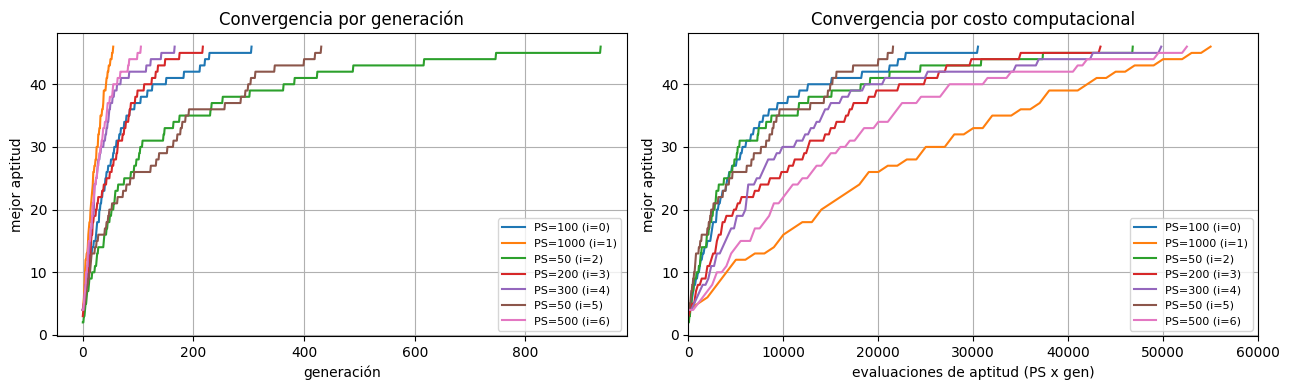

In [11]:
# Curvas de convergencia (mejor aptitud por generación, primera repetición de cada PS)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, ps in enumerate(PS):
    h = historiales[i][0]
    ax[0].plot(h, label=f"PS={ps} (i={i})")
    ax[1].plot(np.arange(len(h)) * ps, h, label=f"PS={ps} (i={i})")
ax[0].set(xlabel="generación", ylabel="mejor aptitud", title="Convergencia por generación")
ax[1].set(xlabel="evaluaciones de aptitud (PS x gen)", ylabel="mejor aptitud",
          title="Convergencia por costo computacional", xlim=(0, 60000))
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusión Actividad 1.** Todos los tamaños de la lista encuentran la cadena, pero el costo es muy distinto:

* Las poblaciones grandes (500 y 1000) convergen en pocas generaciones, pero cada generación es cara: terminan haciendo entre 1.8 y 2.5 veces más evaluaciones de aptitud que la mejor. Para este problema (fitness barato, 46 genes, alfabeto de 83 símbolos) esa diversidad extra no se aprovecha.
* Las poblaciones chicas (50 y 100) necesitan cientos de generaciones, pero el total de evaluaciones es el menor. La contra es una mayor variabilidad entre corridas (ver la columna `gen_desvio`; además las dos entradas de PS=50 de la lista dan promedios distintos), porque con pocos individuos el avance depende más de la suerte de la mutación.
* El programa elige automáticamente el elemento de `PS` con menos evaluaciones promedio: PS = 50 (i = 2), prácticamente empatado con PS = 100. Si el criterio fuera "menos generaciones" ganaría PS = 1000, por eso es importante definir el criterio antes de comparar.

---
# ACTIVIDAD 2 - Optimizar funciones en el espacio

## 2.a - Mínimo de $f(x,y)=(x-1)^2+(x-y)^4$ con selección por rueda de ruleta

Esta función es $\ge 0$ y vale 0 sólo en $(1, 1)$, que es su mínimo global. Siguiendo el ejemplo de la diapositiva "Rueda", usamos **codificación binaria**:

* Individuo: cadena de `2 * NBITS` bits. Los primeros `NBITS` codifican $x$ y los siguientes $y$.
* Decodificación: el entero $n$ que representan los bits se mapea linealmente al intervalo $[a,b]$: $x = a + n \cdot \frac{b-a}{2^{NBITS}-1}$.
* Función de aptitud: la ruleta necesita valores **positivos y a maximizar**, pero queremos **minimizar** $f$. Se usa la transformación
  $$\text{aptitud}(x,y) = \frac{1}{1 + f(x,y)} \in (0, 1]$$
  que vale 1 exactamente en el mínimo y decrece cuando $f$ crece.
* Selección por ruleta: a cada individuo se le asigna la probabilidad $P(i) = \dfrac{\text{aptitud}_i}{\sum_j \text{aptitud}_j}$; se sortea $r \in [0,1)$ y se recorre la probabilidad acumulada hasta superarlo (tal como se describe en la nota del TP).
* Cruzamiento: de un punto sobre la cadena de bits. **Mutación:** inversión de bit (bit-flip) con probabilidad `pm` por bit.

In [12]:
# ============================================================
# ACTIVIDAD 2.a - Definición del problema
# ============================================================
def f_a(x, y):
    return (x - 1) ** 2 + (x - y) ** 4

NBITS = 16                    # bits por variable
DOM_A = (-5.0, 5.0)           # dominio de búsqueda para x e y
NGENES = 2 * NBITS            # longitud del cromosoma binario

# Potencias de 2 para convertir bits -> entero (bit más significativo primero)
POTENCIAS = 2 ** np.arange(NBITS - 1, -1, -1)

def decodificar_bin(poblacion, dominio=DOM_A, nbits=NBITS):
    """Convierte la matriz de bits (n, 2*nbits) en una matriz (n, 2) de valores reales (x, y)."""
    a, b = dominio
    xs = (poblacion[:, :nbits] @ POTENCIAS) * (b - a) / (2 ** nbits - 1) + a
    ys = (poblacion[:, nbits:] @ POTENCIAS) * (b - a) / (2 ** nbits - 1) + a
    return np.column_stack([xs, ys])

def bits_a_str(ind):
    return "".join(str(b) for b in ind)

### Etapa 1 - Población inicial (bits aleatorios)

In [13]:
def poblacion_inicial_bin(ps, ngenes, rng):
    """Matriz (ps, ngenes) de 0/1 aleatorios."""
    return rng.integers(0, 2, size=(ps, ngenes))

### Etapa 2 - Función de aptitud

In [14]:
def aptitud_a(poblacion):
    """Aptitud = 1 / (1 + f). Positiva y a maximizar (mayor aptitud <=> menor f)."""
    xy = decodificar_bin(poblacion)
    return 1.0 / (1.0 + f_a(xy[:, 0], xy[:, 1]))

### Etapa 3 - Selección por rueda de ruleta
Se muestran dos implementaciones equivalentes: una "literal" con el bucle de la nota del TP (para un individuo), y una vectorizada con `np.searchsorted` que se usa en el ciclo principal.

In [15]:
def ruleta_un_individuo(prob_acum, r):
    """Versión literal: recorre la probabilidad acumulada hasta que supera r."""
    for i, pa in enumerate(prob_acum):
        if pa > r:
            return i
    return len(prob_acum) - 1

def seleccion_ruleta(poblacion, aptitud, rng, n_padres=None):
    """Selección proporcional a la aptitud (rueda de ruleta). Devuelve los padres."""
    n = len(poblacion) if n_padres is None else n_padres
    prob = aptitud / aptitud.sum()           # porción de la ruleta de cada individuo
    prob_acum = np.cumsum(prob)              # ruleta "desplegada" en [0, 1]
    r = rng.random(n)                        # n tiradas de la ruleta
    idx = np.searchsorted(prob_acum, r, side="right")   # primer acumulado que supera r
    idx = np.minimum(idx, len(poblacion) - 1)           # protección por redondeo
    return poblacion[idx]

# --- Tabla "Rueda" como la de la diapositiva, para una población pequeña de ejemplo ---
pob_demo = poblacion_inicial_bin(4, NGENES, np.random.default_rng(3))
xy_demo = decodificar_bin(pob_demo)
apt_demo = aptitud_a(pob_demo)
tabla = pd.DataFrame({
    "x (bin)": [bits_a_str(ind[:NBITS]) for ind in pob_demo],
    "y (bin)": [bits_a_str(ind[NBITS:]) for ind in pob_demo],
    "x": xy_demo[:, 0], "y": xy_demo[:, 1],
    "f(x,y)": f_a(xy_demo[:, 0], xy_demo[:, 1]),
    "aptitud": apt_demo,
    "probabilidad": apt_demo / apt_demo.sum(),
    "prob. acumulada": np.cumsum(apt_demo / apt_demo.sum()),
})
r_demo = 0.42
print(f"Tirada r = {r_demo} -> se selecciona el individuo {ruleta_un_individuo(tabla['prob. acumulada'].values, r_demo)}")
tabla

Tirada r = 0.42 -> se selecciona el individuo 1


,x (bin),y (bin),x,y,"f(x,y)",aptitud,probabilidad,prob. acumulada
0,1000011100001000,1100001100110111,0.2747,2.6257,31.0737,0.0312,0.1581,0.1581
1,1001111010011000,0111000100011000,1.1952,-0.5822,10.0177,0.0908,0.4604,0.6185
2,1111101100010110,0111010110110100,4.8082,-0.4022,751.5000,0.0013,0.0067,0.6252
3,1110100001101100,1100011010010101,4.0791,2.7572,12.5343,0.0739,0.3748,1.0000


### Etapa 4 - Cruzamiento de un punto sobre bits
Se reutiliza `cruce_un_punto` de la Actividad 1 (es independiente del tipo de gen).
### Etapa 5 - Mutación por inversión de bit

In [16]:
def mutacion_bin(hijos, rng, pm):
    """Bit-flip: cada bit se invierte con probabilidad pm."""
    mascara = rng.random(hijos.shape) < pm
    hijos[mascara] = 1 - hijos[mascara]
    return hijos

### Ciclo completo del AG (2.a)

In [17]:
def ag_minimo_ruleta(ps=100, n_gen=200, pc=0.9, pm=None, rng=None):
    rng = np.random.default_rng(SEMILLA) if rng is None else rng
    pm = 1.0 / NGENES if pm is None else pm

    pob = poblacion_inicial_bin(ps, NGENES, rng)      # 1. Población
    apt = aptitud_a(pob)                               # 2. Aptitud
    hist_f = []
    for gen in range(n_gen):
        elite = pob[apt.argmax()].copy()
        padres = seleccion_ruleta(pob, apt, rng)        # 3. Selección por RULETA
        hijos = cruce_un_punto(padres, rng, pc)         # 4. Cruzamiento de un punto
        hijos = mutacion_bin(hijos, rng, pm)            # 5. Mutación bit-flip
        apt_h = aptitud_a(hijos)
        hijos[apt_h.argmin()] = elite                   # elitismo
        pob, apt = hijos, aptitud_a(hijos)
        xy_best = decodificar_bin(pob[apt.argmax()][None, :])[0]
        hist_f.append(f_a(*xy_best))
    mejor = decodificar_bin(pob[apt.argmax()][None, :])[0]
    return mejor, np.array(hist_f), pob

mejor_a, hist_a, pob_final_a = ag_minimo_ruleta()
print(f"Mínimo aproximado: x = {mejor_a[0]:.5f}, y = {mejor_a[1]:.5f}, f = {f_a(*mejor_a):.3e}")
print("Mínimo exacto    : x = 1, y = 1, f = 0")

Mínimo aproximado: x = 1.00015, y = 0.99969, f = 2.328e-08
Mínimo exacto    : x = 1, y = 1, f = 0


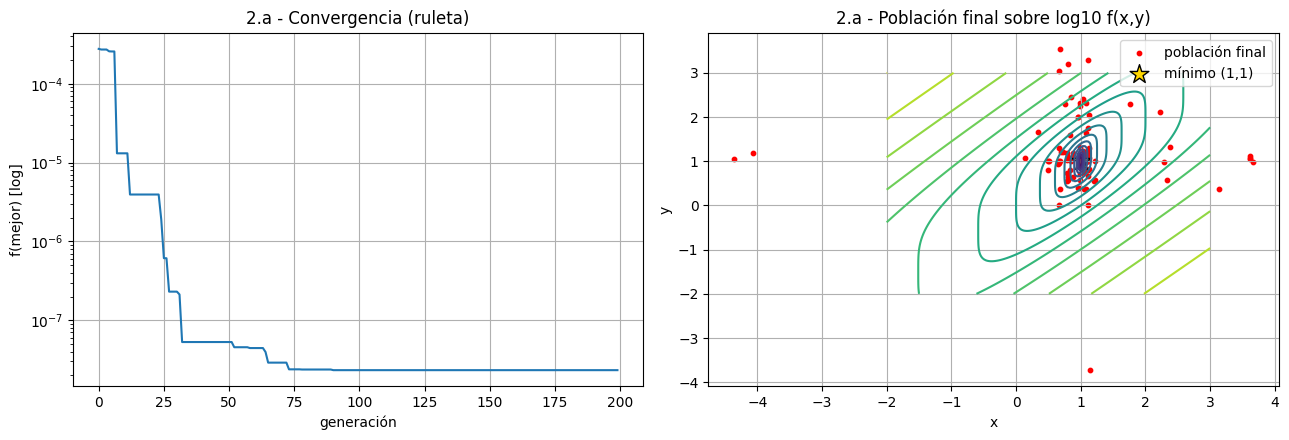

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogy(hist_a); ax[0].set(xlabel="generación", ylabel="f(mejor) [log]", title="2.a - Convergencia (ruleta)")

X, Y = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-2, 3, 200))
cs = ax[1].contour(X, Y, np.log10(f_a(X, Y) + 1e-9), levels=20, cmap="viridis")
xy_f = decodificar_bin(pob_final_a)
ax[1].scatter(xy_f[:, 0], xy_f[:, 1], s=10, c="red", label="población final")
ax[1].scatter([1], [1], marker="*", s=200, c="gold", edgecolor="k", label="mínimo (1,1)")
ax[1].set(xlabel="x", ylabel="y", title="2.a - Población final sobre log10 f(x,y)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2.b - Máximo de $f(x,y)=2+\sqrt{9-x^2-y^2}$ (parte real) con un método diferente

La raíz sólo es real dentro del disco $x^2+y^2 \le 9$, por lo que el problema tiene una **restricción**. El máximo es $f(0,0)=5$ (la "cúpula" de la figura del TP).

Cambios respecto del ejercicio anterior (método diferente):
* Codificación real: cada individuo es un vector $(x, y)$ de números flotantes (no hay que decodificar bits).
* Selección por rango lineal: los individuos se ordenan por aptitud y la probabilidad de selección depende de la **posición** (rango) y no del valor de la aptitud. Esto evita el problema de la ruleta de que un individuo dominante acapare la población en pocas generaciones.
* Cruzamiento aritmético: $h_1 = \alpha p_1 + (1-\alpha) p_2$, $h_2 = (1-\alpha) p_1 + \alpha p_2$ con $\alpha \sim U(0,1)$ (los hijos son puntos intermedios entre los padres).
* Mutación gaussiana: a cada gen se le suma ruido $N(0,\sigma)$ con probabilidad `pm`.
* Restricción mediante penalización: si $9-x^2-y^2<0$ el individuo es infactible y su aptitud es $2-(x^2+y^2-9)$, siempre menor que la de cualquier factible (que vale al menos 2) y peor cuanto más lejos está del disco. Así la población es "empujada" hacia la región factible.

**Función de aptitud:**
$$\text{aptitud}(x,y)=\begin{cases} 2+\sqrt{9-x^2-y^2} & \text{si } 9-x^2-y^2\ge 0 \\ 2-(x^2+y^2-9) & \text{en otro caso (penalización)}\end{cases}$$

In [19]:
# ============================================================
# ACTIVIDAD 2.b - Definición del problema
# ============================================================
DOM_B = (-4.0, 4.0)

def f_b(x, y):
    """Parte real de 2 + sqrt(9 - x^2 - y^2) (NaN fuera del disco)."""
    return 2 + np.sqrt(9 - x ** 2 - y ** 2)

def aptitud_b(poblacion):
    """Aptitud con penalización para los puntos fuera del disco x^2 + y^2 <= 9."""
    x, y = poblacion[:, 0], poblacion[:, 1]
    radicando = 9 - x ** 2 - y ** 2
    factible = radicando >= 0
    apt = np.empty(len(poblacion))
    apt[factible] = 2 + np.sqrt(radicando[factible])      # valor real de f
    apt[~factible] = 2 - (-radicando[~factible])          # 2 - exceso fuera del disco (< 2)
    return apt

### Etapa 1 - Población inicial real

In [20]:
def poblacion_inicial_real(ps, n_var, dominio, rng):
    """Matriz (ps, n_var) de reales uniformes en el dominio dado."""
    lo, hi = dominio
    return rng.uniform(lo, hi, size=(ps, n_var))

### Etapa 3 - Selección por rango lineal
Se ordena la población de peor a mejor; el individuo en la posición $i$ (0 = peor) recibe probabilidad $P_i = \dfrac{2 - s}{N} + \dfrac{2 i (s - 1)}{N (N - 1)}$ con presión selectiva $s \in [1, 2]$ (con $s=2$ el mejor tiene el doble de probabilidad que la media y el peor, probabilidad 0). Luego se sortea con esas probabilidades (ruleta sobre los rangos).

In [21]:
def seleccion_rango(poblacion, aptitud, rng, s=1.8, n_padres=None):
    """Selección por rango lineal con presión selectiva s (1 <= s <= 2)."""
    n = len(poblacion) if n_padres is None else n_padres
    N = len(poblacion)
    orden = np.argsort(aptitud)                     # índices de peor a mejor
    rangos = np.empty(N); rangos[orden] = np.arange(N)   # rango de cada individuo (0 = peor)
    prob = (2 - s) / N + 2 * rangos * (s - 1) / (N * (N - 1))
    idx = rng.choice(N, size=n, p=prob / prob.sum())
    return poblacion[idx]

### Etapas 4 y 5: cruzamiento aritmético y mutación gaussiana

In [22]:
def cruce_aritmetico(padres, rng, pc=0.9):
    """Cruzamiento aritmético (blend) para codificación real."""
    n = len(padres)
    if n % 2 == 1:
        padres = np.vstack([padres, padres[-1:]])
    p1, p2 = padres[0::2], padres[1::2]
    alfa = rng.random((len(p1), 1))                  # un alfa por par
    cruza = rng.random((len(p1), 1)) < pc
    h1 = np.where(cruza, alfa * p1 + (1 - alfa) * p2, p1)
    h2 = np.where(cruza, (1 - alfa) * p1 + alfa * p2, p2)
    hijos = np.empty_like(padres)
    hijos[0::2], hijos[1::2] = h1, h2
    return hijos[:n]

def mutacion_gaussiana(hijos, rng, pm, sigma, dominio=None):
    """Suma ruido N(0, sigma) a cada gen con probabilidad pm; opcionalmente recorta al dominio."""
    mascara = rng.random(hijos.shape) < pm
    hijos = hijos + mascara * rng.normal(0, sigma, size=hijos.shape)
    if dominio is not None:
        hijos = np.clip(hijos, dominio[0], dominio[1])
    return hijos

### Ciclo completo del AG (2.b)

In [23]:
def ag_maximo_rango(ps=80, n_gen=150, pc=0.9, pm=0.2, sigma=0.3, s=1.8, rng=None):
    rng = np.random.default_rng(SEMILLA) if rng is None else rng
    pob = poblacion_inicial_real(ps, 2, DOM_B, rng)     # 1. Población inicial en [-4,4] x [-4,4]
    apt = aptitud_b(pob)                                # 2. Aptitud (con penalización)
    hist = []
    for gen in range(n_gen):
        elite = pob[apt.argmax()].copy()
        padres = seleccion_rango(pob, apt, rng, s=s)    # 3. Selección por RANGO
        hijos = cruce_aritmetico(padres, rng, pc)       # 4. Cruzamiento aritmético
        hijos = mutacion_gaussiana(hijos, rng, pm, sigma, DOM_B)   # 5. Mutación gaussiana
        apt_h = aptitud_b(hijos)
        hijos[apt_h.argmin()] = elite                   # elitismo
        pob, apt = hijos, aptitud_b(hijos)
        hist.append(apt.max())
    return pob[apt.argmax()], np.array(hist), pob

mejor_b, hist_b, pob_final_b = ag_maximo_rango()
print(f"Máximo aproximado: x = {mejor_b[0]:.5f}, y = {mejor_b[1]:.5f}, f = {f_b(*mejor_b):.6f}")
print("Máximo exacto    : x = 0, y = 0, f = 5")
print("Individuos factibles en la población final:", int(((pob_final_b ** 2).sum(axis=1) <= 9).sum()), "/", len(pob_final_b))

Máximo aproximado: x = -0.00004, y = 0.00000, f = 5.000000
Máximo exacto    : x = 0, y = 0, f = 5
Individuos factibles en la población final: 80 / 80


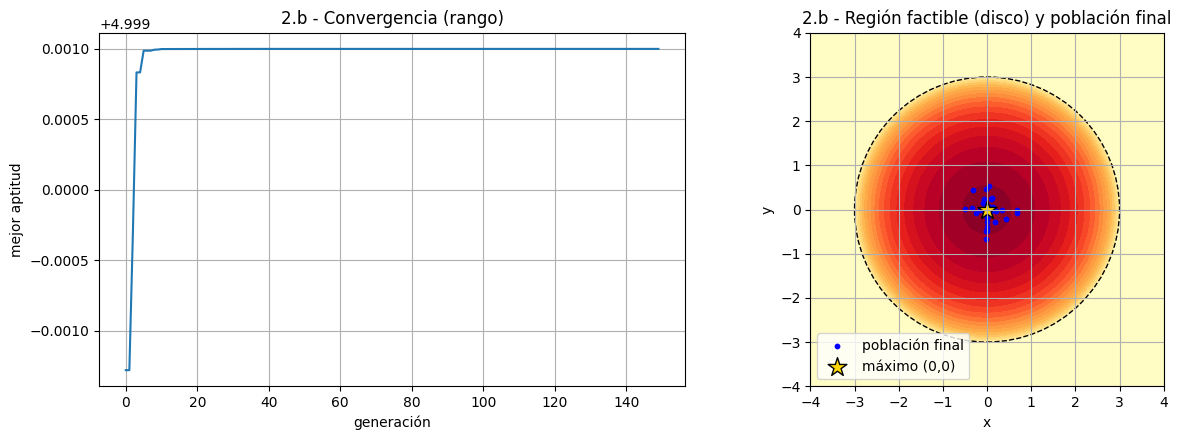

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(hist_b); ax[0].set(xlabel="generación", ylabel="mejor aptitud", title="2.b - Convergencia (rango)")
X, Y = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
Z = np.where(X**2 + Y**2 <= 9, 2 + np.sqrt(np.clip(9 - X**2 - Y**2, 0, None)), 2)
ax[1].contourf(X, Y, Z, levels=20, cmap="YlOrRd")
ax[1].add_patch(plt.Circle((0, 0), 3, fill=False, ls="--", color="k"))
ax[1].scatter(pob_final_b[:, 0], pob_final_b[:, 1], s=10, c="blue", label="población final")
ax[1].scatter([0], [0], marker="*", s=200, c="gold", edgecolor="k", label="máximo (0,0)")
ax[1].set(xlabel="x", ylabel="y", title="2.b - Región factible (disco) y población final", aspect="equal"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

## 2.c - Máximo de $f(x,y,z)=z-x^2-15y^2$ con $-2<x,y,z<11$

Analíticamente: $-x^2$ y $-15y^2$ se maximizan en $x=y=0$ y $z$ debe ser lo más grande posible, por lo que el máximo está en el borde $z \to 11$, con $f \to 11$ (la desigualdad es estricta, así que el óptimo se aproxima desde adentro).

**Modelado:**
* Individuo: vector real $(x, y, z)$.
* Función de aptitud: la propia $f(x,y,z)$ (se maximiza directamente; el torneo no necesita valores positivos).
* Restricción de caja: la población inicial se genera dentro del dominio y, tras cada mutación, los genes se recortan a $(-2+\varepsilon,\, 11-\varepsilon)$ para respetar la desigualdad estricta.
* Selección por torneo (k = 3) + elitismo; **cruzamiento aritmético**; **mutación gaussiana** con $\sigma$ que decrece con las generaciones (al principio explora, al final afina).

Máximo aproximado: x = -0.00005, y = -0.00001, z = 11.00000, f = 11.000000
Máximo teórico   : x = 0, y = 0, z -> 11, f -> 11


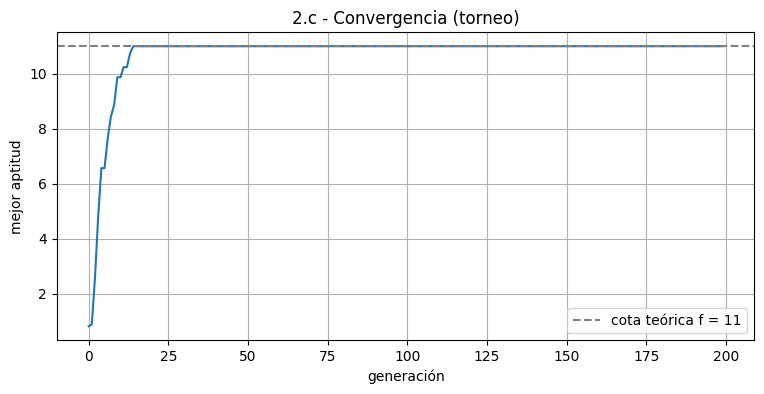

In [25]:
# ============================================================
# ACTIVIDAD 2.c - Definición del problema
# ============================================================
EPS = 1e-9
DOM_C = (-2.0 + EPS, 11.0 - EPS)     # intervalo abierto (-2, 11) aproximado

def f_c(x, y, z):
    return z - x ** 2 - 15 * y ** 2

def aptitud_c(poblacion):
    """Aptitud = f(x, y, z) directamente (se maximiza)."""
    return f_c(poblacion[:, 0], poblacion[:, 1], poblacion[:, 2])

def ag_maximo_3d(ps=100, n_gen=200, pc=0.9, pm=0.3, sigma0=1.0, k=3, rng=None):
    rng = np.random.default_rng(SEMILLA) if rng is None else rng
    pob = poblacion_inicial_real(ps, 3, DOM_C, rng)      # 1. Población inicial en (-2, 11) para x, y, z
    apt = aptitud_c(pob)                                 # 2. Aptitud
    hist = []
    for gen in range(n_gen):
        sigma = sigma0 * (1 - gen / n_gen) + 0.01        # desviación de la mutación decreciente
        elite = pob[apt.argmax()].copy()
        padres = seleccion_torneo(pob, apt, rng, k=k)    # 3. Selección por TORNEO
        hijos = cruce_aritmetico(padres, rng, pc)        # 4. Cruzamiento aritmético
        hijos = mutacion_gaussiana(hijos, rng, pm, sigma, DOM_C)   # 5. Mutación + recorte al dominio
        apt_h = aptitud_c(hijos)
        hijos[apt_h.argmin()] = elite                    # elitismo
        pob, apt = hijos, aptitud_c(hijos)
        hist.append(apt.max())
    return pob[apt.argmax()], np.array(hist)

mejor_c, hist_c = ag_maximo_3d()
print(f"Máximo aproximado: x = {mejor_c[0]:.5f}, y = {mejor_c[1]:.5f}, z = {mejor_c[2]:.5f}, f = {f_c(*mejor_c):.6f}")
print("Máximo teórico   : x = 0, y = 0, z -> 11, f -> 11")

plt.plot(hist_c); plt.axhline(11, ls="--", c="gray", label="cota teórica f = 11")
plt.xlabel("generación"); plt.ylabel("mejor aptitud"); plt.title("2.c - Convergencia (torneo)"); plt.legend(); plt.show()

---
# ACTIVIDAD 3 - Selección de variables con AG (dataset *Wine*)

El artículo de **Zachary Warnes** ("*Feature Selection with Genetic Algorithms*", Towards Data Science, 2021) plantea la selección de variables como un problema de búsqueda: cada individuo es una **máscara binaria** que indica qué columnas del dataset se usan, y la aptitud es el **desempeño de un clasificador** entrenado sólo con esas columnas (enfoque *wrapper*). En el artículo se usa el paquete `sklearn-genetic` (`GeneticSelectionCV`) sobre el dataset de cáncer de mama, probando varios clasificadores y comparando el subconjunto del AG contra usar todas las variables y contra las 5 mejores según chi2. El AG de esa librería usa selección por torneo, cruce, mutación por inversión de bits y un límite de variables (`max_features`). Acá se programan esas mismas etapas a mano, sobre Wine y con regresión logística, para poder identificarlas.

**Dataset Wine** (`sklearn.datasets.load_wine`): 178 vinos, **13 variables químicas** y 3 clases (cultivares). Hay $2^{13}-1 = 8191$ subconjuntos posibles de variables.

### Modelado
* Individuo: vector de 13 bits; el bit $j = 1$ significa "usar la variable $j$".
* Función de aptitud: *accuracy* promedio de **validación cruzada estratificada (5 folds)** de una regresión logística (con estandarización) entrenada sobre las variables seleccionadas, calculada sobre el conjunto de *entrenamiento*. Se resta una pequeña penalización `LAMBDA * n_variables` para preferir, a igual accuracy, los subconjuntos más chicos (modelos más simples, como pide la consigna). Un individuo sin variables tiene aptitud 0.
* Como la aptitud es costosa (entrena 5 modelos), se **cachea** por máscara, igual que hace `GeneticSelectionCV` con `caching=True`.

### Etapas pedidas por la consigna (identificadas en el código)
| Etapa | Implementación |
|---|---|
| Seleccionar | `seleccionar()` - torneo de tamaño 3 |
| Cruzar | `cruzar()` - cruce uniforme (cada bit viene de uno u otro padre con prob. 0.5) |
| Mutar | `mutar()` - inversión de bit con probabilidad `PM` por gen |
| Reemplazar | `reemplazar()` - reemplazo generacional con elitismo (los `N_ELITE` mejores padres sobreviven) |

In [26]:
# ============================================================
# ACTIVIDAD 3 - Datos y función de aptitud
# ============================================================
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, chi2

wine = load_wine()
X_all, y_all = wine.data, wine.target
NOMBRES = np.array(wine.feature_names, dtype=object)
N_FEAT = X_all.shape[1]

def nombres(mascara):
    """Lista de nombres de las variables activas en una máscara binaria."""
    return NOMBRES[mascara.astype(bool)].tolist()

print("Muestras:", X_all.shape[0], "| variables:", N_FEAT, "| clases:", np.bincount(y_all))
print("Variables:", NOMBRES.tolist())

# Partición: el AG trabaja SOLO con train (validación cruzada interna); test queda para la evaluación final.
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all, random_state=SEMILLA)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
LAMBDA = 0.002            # penalización por variable usada (0.2 puntos de accuracy cada 1 variable)

def modelo():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

_cache = {}
def aptitud_mascara(mascara):
    """Aptitud de UNA máscara: accuracy CV (5 folds) en train - LAMBDA * n_variables. Con caché."""
    clave = mascara.tobytes()
    if clave not in _cache:
        if mascara.sum() == 0:
            _cache[clave] = 0.0
        else:
            acc = cross_val_score(modelo(), X_tr[:, mascara.astype(bool)], y_tr, cv=CV, scoring="accuracy").mean()
            _cache[clave] = acc - LAMBDA * mascara.sum()
    return _cache[clave]

def aptitud_poblacion(poblacion):
    return np.array([aptitud_mascara(ind) for ind in poblacion])

def accuracy_cv(mascara):
    """Accuracy CV 'pura' (sin penalización) para reportar."""
    return cross_val_score(modelo(), X_tr[:, mascara.astype(bool)], y_tr, cv=CV, scoring="accuracy").mean()

todas = np.ones(N_FEAT, dtype=int)
print(f"\nAccuracy CV (train) usando las 13 variables: {accuracy_cv(todas):.4f}")

Muestras: 178 | variables: 13 | clases: [59 71 48]
Variables: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Accuracy CV (train) usando las 13 variables: 0.9673


### Etapa 1 - Población inicial
Cada bit se inicializa en 1 con probabilidad 0.5. Si un individuo queda sin variables se le activa una al azar.

In [27]:
def poblacion_inicial_fs(ps, rng):
    pob = rng.integers(0, 2, size=(ps, N_FEAT))
    for ind in pob:                              # evitar individuos vacíos
        if ind.sum() == 0:
            ind[rng.integers(N_FEAT)] = 1
    return pob

### Etapa SELECCIONAR - torneo

In [28]:
def seleccionar(poblacion, aptitud, rng, k=3):
    """SELECCIONAR: torneo de tamaño k. Devuelve tantos padres como individuos hay."""
    return seleccion_torneo(poblacion, aptitud, rng, k=k)

### Etapa CRUZAR - cruce uniforme
Para cada par de padres y cada bit se sortea de qué padre lo hereda cada hijo (probabilidad 0.5). Es el operador que usa `GeneticSelectionCV` (`crossover_independent_proba`). Se aplica con probabilidad `pc` por par.

In [29]:
def cruzar(padres, rng, pc=0.7):
    """CRUZAR: cruce uniforme bit a bit."""
    n = len(padres)
    if n % 2 == 1:
        padres = np.vstack([padres, padres[-1:]])
    p1, p2 = padres[0::2], padres[1::2]
    cruza = (rng.random((len(p1), 1)) < pc)
    mascara = (rng.random(p1.shape) < 0.5) | ~cruza          # True -> gen del primer padre
    h1 = np.where(mascara, p1, p2)
    h2 = np.where(mascara, p2, p1)
    hijos = np.empty_like(padres)
    hijos[0::2], hijos[1::2] = h1, h2
    return hijos[:n]

### Etapa MUTAR - inversión de bit

In [30]:
def mutar(hijos, rng, pm=0.08):
    """MUTAR: invierte cada bit con probabilidad pm (activa/desactiva una variable)."""
    mascara = rng.random(hijos.shape) < pm
    hijos[mascara] = 1 - hijos[mascara]
    for ind in hijos:                              # evitar individuos vacíos
        if ind.sum() == 0:
            ind[rng.integers(N_FEAT)] = 1
    return hijos

### Etapa REEMPLAZAR - generacional con elitismo
La nueva población son los hijos, pero los `n_elite` mejores individuos de la generación anterior reemplazan a los `n_elite` peores hijos. Así la mejor solución nunca se pierde.

In [31]:
def reemplazar(poblacion, aptitud, hijos, aptitud_hijos, n_elite=2):
    """REEMPLAZAR: los hijos pasan a ser la nueva población; sobrevive la élite de los padres."""
    nueva = hijos.copy(); apt_nueva = aptitud_hijos.copy()
    idx_elite = np.argsort(aptitud)[-n_elite:]          # mejores padres
    idx_peores = np.argsort(apt_nueva)[:n_elite]         # peores hijos
    nueva[idx_peores] = poblacion[idx_elite]
    apt_nueva[idx_peores] = aptitud[idx_elite]
    return nueva, apt_nueva

### Ciclo completo del AG de selección de variables

In [32]:
def ag_seleccion_variables(n_gen, ps=30, pc=0.7, pm=0.08, k=3, n_elite=2, semilla=SEMILLA, verbose=False):
    rng = np.random.default_rng(semilla)
    pob = poblacion_inicial_fs(ps, rng)                 # 1. Población
    apt = aptitud_poblacion(pob)                        # 2. Aptitud
    hist = [apt.max()]
    for gen in range(n_gen):
        padres = seleccionar(pob, apt, rng, k)          # SELECCIONAR
        hijos = cruzar(padres, rng, pc)                 # CRUZAR
        hijos = mutar(hijos, rng, pm)                   # MUTAR
        apt_h = aptitud_poblacion(hijos)
        pob, apt = reemplazar(pob, apt, hijos, apt_h, n_elite)   # REEMPLAZAR
        hist.append(apt.max())
        if verbose:
            print(f"gen {gen+1:3d} | mejor aptitud {apt.max():.4f} | variables: {int(pob[apt.argmax()].sum())}")
    mejor = pob[apt.argmax()]
    return mejor, np.array(hist)

mejor_demo, _ = ag_seleccion_variables(n_gen=5, verbose=True)
print("Mejor subconjunto:", nombres(mejor_demo))

gen   1 | mejor aptitud 0.9780 | variables: 7


gen   2 | mejor aptitud 0.9820 | variables: 5


gen   3 | mejor aptitud 0.9820 | variables: 5


gen   4 | mejor aptitud 0.9820 | variables: 5


gen   5 | mejor aptitud 0.9820 | variables: 5
Mejor subconjunto: ['alcohol', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


### Prueba con distintos números de generaciones
Se corre el AG con **2, 5, 10, 20 y 40 generaciones**, y para que el resultado no dependa de la suerte de una sola población inicial, cada configuración se repite con **5 semillas distintas** (población de 20 individuos). Para el mejor subconjunto de cada corrida se reporta: cantidad de variables, aptitud, accuracy CV en train y accuracy en el conjunto de **test** (nunca visto por el AG). Se compara contra usar **todas** las variables y contra las **5 mejores por el test chi2** (`SelectKBest`), tal como hace el artículo.

In [33]:
def accuracy_test(mascara):
    m = mascara.astype(bool)
    return modelo().fit(X_tr[:, m], y_tr).score(X_te[:, m], y_te)

GENERACIONES = [2, 5, 10, 20, 40]
SEMILLAS = [0, 1, 2, 3, 4]
PS_FS = 20

corridas, historiales_fs = [], {}
for ng in GENERACIONES:
    for s in SEMILLAS:
        mejor, hist = ag_seleccion_variables(n_gen=ng, ps=PS_FS, semilla=s)
        historiales_fs[(ng, s)] = hist
        corridas.append({"generaciones": ng, "semilla": s, "n_variables": int(mejor.sum()),
                         "aptitud": aptitud_mascara(mejor), "acc_cv_train": accuracy_cv(mejor),
                         "acc_test": accuracy_test(mejor),
                         "gen_mejor": int(np.argmax(hist)),          # generación en que apareció el mejor
                         "variables": ", ".join(nombres(mejor))})
df_corridas_fs = pd.DataFrame(corridas)
print("Evaluaciones de aptitud distintas calculadas (caché):", len(_cache))

# Mejor aptitud global encontrada en todas las corridas (referencia para medir "éxito")
APT_MAX = df_corridas_fs["aptitud"].max()
resumen_fs = (df_corridas_fs.groupby("generaciones")
              .agg(aptitud_prom=("aptitud", "mean"), aptitud_max=("aptitud", "max"),
                   n_var_prom=("n_variables", "mean"), acc_cv_prom=("acc_cv_train", "mean"),
                   acc_test_prom=("acc_test", "mean"),
                   corridas_optimas=("aptitud", lambda a: f"{int((a >= APT_MAX - 1e-9).sum())}/{len(a)}"))
              .reset_index())
resumen_fs

Evaluaciones de aptitud distintas calculadas (caché): 1152


,generaciones,aptitud_prom,aptitud_max,n_var_prom,acc_cv_prom,acc_test_prom,corridas_optimas
0,2,0.9792,0.982,6.4,0.992,0.9593,0/5
1,5,0.9808,0.982,5.6,0.992,0.9667,0/5
2,10,0.9824,0.984,4.8,0.992,0.9444,2/5
3,20,0.9832,0.984,4.4,0.992,0.9296,3/5
4,40,0.9836,0.984,4.2,0.992,0.9148,4/5


In [34]:
# Líneas de base (sin AG) para comparar
chi2_sel = SelectKBest(chi2, k=5).fit(X_tr, y_tr)
mascara_chi2 = chi2_sel.get_support().astype(int)
mejor_global = df_corridas_fs.sort_values(["aptitud", "n_variables"], ascending=[False, True]).iloc[0]
mascara_ag = np.isin(NOMBRES, mejor_global.variables.split(", ")).astype(int)

base = pd.DataFrame([
    {"método": "Todas las variables", "n_variables": N_FEAT,
     "acc_cv_train": accuracy_cv(todas), "acc_test": accuracy_test(todas), "variables": "todas"},
    {"método": "Filtro chi2 (top-5)", "n_variables": 5,
     "acc_cv_train": accuracy_cv(mascara_chi2), "acc_test": accuracy_test(mascara_chi2),
     "variables": ", ".join(nombres(mascara_chi2))},
    {"método": f"AG (mejor corrida: {mejor_global.generaciones} gen., semilla {mejor_global.semilla})",
     "n_variables": int(mascara_ag.sum()),
     "acc_cv_train": accuracy_cv(mascara_ag), "acc_test": accuracy_test(mascara_ag),
     "variables": ", ".join(nombres(mascara_ag))},
])
base

,método,n_variables,acc_cv_train,acc_test,variables
0,Todas las variables,13,0.9673,0.9815,todas
1,Filtro chi2 (top-5),5,0.9760,0.9259,"malic_acid, magnesium, flavanoids, color_inten..."
2,"AG (mejor corrida: 10 gen., semilla 1)",4,0.9920,0.9074,"ash, flavanoids, color_intensity, proline"


In [35]:
# Detalle: subconjunto elegido en cada corrida
for _, f in df_corridas_fs.iterrows():
    print(f"{f.generaciones:3d} gen | semilla {f.semilla} | aptitud {f.aptitud:.4f} | {f.n_variables} var: {f.variables}")

  2 gen | semilla 0 | aptitud 0.9780 | 7 var: alcohol, malic_acid, total_phenols, nonflavanoid_phenols, color_intensity, od280/od315_of_diluted_wines, proline
  2 gen | semilla 1 | aptitud 0.9800 | 6 var: alcohol, malic_acid, flavanoids, color_intensity, hue, proline
  2 gen | semilla 2 | aptitud 0.9780 | 7 var: alcohol, malic_acid, magnesium, flavanoids, color_intensity, hue, proline
  2 gen | semilla 3 | aptitud 0.9780 | 7 var: alcohol, malic_acid, total_phenols, flavanoids, color_intensity, od280/od315_of_diluted_wines, proline
  2 gen | semilla 4 | aptitud 0.9820 | 5 var: ash, flavanoids, color_intensity, hue, proline
  5 gen | semilla 0 | aptitud 0.9800 | 6 var: alcohol, flavanoids, color_intensity, hue, od280/od315_of_diluted_wines, proline
  5 gen | semilla 1 | aptitud 0.9800 | 6 var: alcohol, malic_acid, flavanoids, color_intensity, od280/od315_of_diluted_wines, proline
  5 gen | semilla 2 | aptitud 0.9800 | 6 var: alcohol, flavanoids, color_intensity, hue, od280/od315_of_dilut

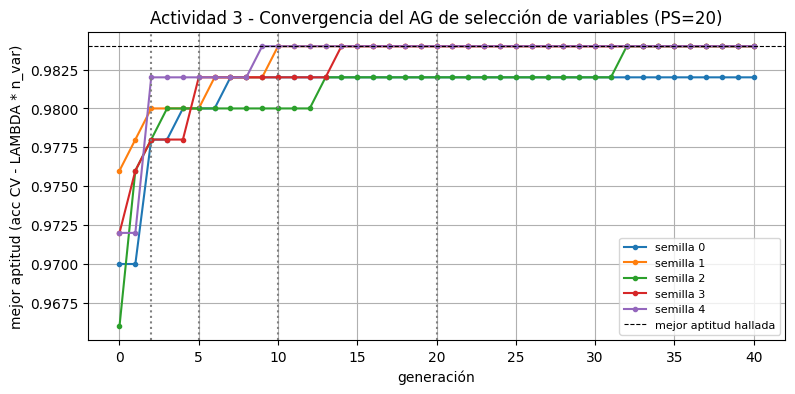

In [36]:
# Convergencia: las corridas de 40 generaciones (una por semilla). Como la semilla fija la población
# inicial y la secuencia aleatoria, la corrida de N generaciones es el "prefijo" de la de 40.
fig, ax = plt.subplots(figsize=(9, 4))
for s in SEMILLAS:
    ax.plot(historiales_fs[(40, s)], marker=".", label=f"semilla {s}")
for ng in GENERACIONES[:-1]:
    ax.axvline(ng, ls=":", c="gray")
ax.axhline(APT_MAX, ls="--", c="k", lw=0.8, label="mejor aptitud hallada")
ax.set(xlabel="generación", ylabel="mejor aptitud (acc CV - LAMBDA * n_var)",
       title="Actividad 3 - Convergencia del AG de selección de variables (PS=20)")
ax.legend(fontsize=8); plt.show()

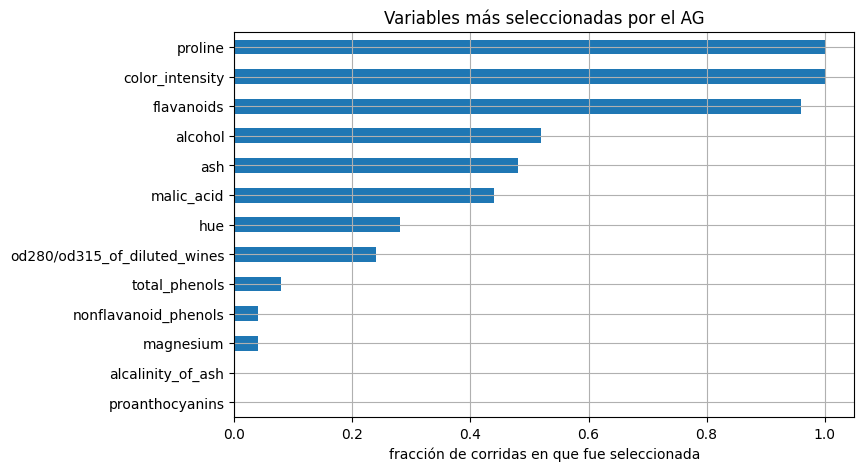

In [37]:
# Frecuencia con la que cada variable aparece en los mejores subconjuntos de todas las corridas (robustez de la selección)
mascaras_ag = np.array([[v in f.split(", ") for v in NOMBRES] for f in df_corridas_fs["variables"]])
frec = pd.Series(mascaras_ag.mean(axis=0), index=NOMBRES.tolist()).sort_values(ascending=False)
frec.plot.barh(figsize=(8, 5)); plt.gca().invert_yaxis()
plt.xlabel("fracción de corridas en que fue seleccionada"); plt.title("Variables más seleccionadas por el AG"); plt.show()

### Reporte de resultados - Actividad 3
* Efecto del número de generaciones. Con 2 generaciones ninguna de las 5 semillas llega a la mejor aptitud hallada y los subconjuntos son más grandes (6.4 variables en promedio). A medida que aumentan las generaciones la aptitud promedio sube y la cantidad de variables baja: con 10 generaciones llegan al óptimo 2 de 5 semillas, con 20 llegan 3 y con 40 llegan 4 (ver la columna `corridas_optimas` y el gráfico de convergencia). Entre 20 y 40 generaciones la mejora es chica, así que más generaciones agregan sobre todo tiempo de cómputo.
* Calidad del subconjunto. El AG encuentra subconjuntos de 4 a 7 variables (4 o 5 cuando se corre con 10 generaciones o más), con accuracy de validación cruzada en train mayor que la de usar todas las variables (0.992 contra 0.967) y mayor que la del filtro chi2 con 5 variables (0.976), porque evalúa las variables en conjunto y no de a una.
* Limitación observada (sobreajuste de la selección). En el conjunto de test, que el AG nunca vio, los subconjuntos elegidos rinden peor que usar todas las variables (entre 0.91 y 0.97 de promedio, contra 0.98). El test tiene sólo 54 muestras, así que la diferencia equivale a entre 1 y 4 vinos mal clasificados, pero la tendencia se ve: con más generaciones sube la aptitud CV y baja el accuracy en test. Esto pasa porque al evaluar cientos de máscaras sobre los mismos folds, el AG termina eligiendo la que mejor se ajusta a esas particiones y no necesariamente la que mejor generaliza (sesgo de selección de los métodos *wrapper*). Para tener una estimación sin ese sesgo habría que usar validación cruzada anidada (el AG adentro de cada fold externo) o un dataset más grande que Wine.
* Variables recurrentes. *color_intensity* y *proline* aparecen en las 25 corridas y *flavanoids* en 24. *alcohol*, *ash* y *malic_acid* aparecen en alrededor de la mitad, y el subconjunto que más se repite con 20 y 40 generaciones es *ash, flavanoids, color_intensity, proline*. *hue* y *od280/od315* aparecen sobre todo en las corridas cortas y se van cuando el AG achica el subconjunto.
* Beneficios logrados, según lo que enumera la consigna: modelo más simple e interpretable (4 o 5 variables en lugar de 13), entrenamiento más rápido y menor dimensionalidad. El beneficio de "reducir overfitting" del modelo final hay que contrastarlo con el sobreajuste del propio proceso de selección descripto arriba.

Las etapas **Seleccionar / Cruzar / Mutar / Reemplazar** están en las funciones `seleccionar`, `cruzar`, `mutar` y `reemplazar`, que se llaman en ese orden dentro de `ag_seleccion_variables`.

---
# Conclusiones generales
* El mismo esqueleto (población, aptitud, selección, cruce, mutación y reemplazo) sirvió para problemas muy distintos: búsqueda combinatoria de texto, optimización continua con y sin restricciones, y selección de variables en aprendizaje automático. Lo que cambia es la **codificación** del individuo y la **función de aptitud**.
* Elección del fitness: debe ser positiva y creciente para la ruleta (por eso $1/(1+f)$ en 2.a), puede incluir **penalizaciones** para manejar restricciones (2.b) o términos de regularización para preferir soluciones simples (Actividad 3).
* Métodos de selección: la ruleta es sencilla pero sensible a la escala y a individuos dominantes; el rango y el torneo son más robustos y permiten controlar la presión selectiva.
* Tamaño de población: no "más grande es mejor": el programa de la Actividad 1 mostró que hay un tamaño intermedio que minimiza el costo total de evaluaciones.
* Elitismo fue clave en todos los casos para que la mejor solución no se pierda por el azar del cruce y la mutación.
* Optimizar no es lo mismo que generalizar: en la Actividad 3 el AG maximizó muy bien su función de aptitud, pero esa aptitud (accuracy CV sobre train) es sólo una estimación; cuando el AG la "exprime" demasiado, la mejora deja de trasladarse a datos nuevos. El diseño de la función de aptitud y de la evaluación es tan importante como el algoritmo.